# Cumulative Theta-Rhythm Disruption Predicts a Reduction in Hippocampal Place-Field Count

**An Exploratory Reanalysis of Public Medial Septal Cooling Data (Dandiset 000059, Petersen & Buzsáki 2020)**  
**Author:** Saad Yusuf  
**Affiliation:** Department of Computer Science, Jamia Millia Islamia, New Delhi, India  
**Correspondence:** `syed.saad7527@gmail.com` | ORCID: `0009-0000-2333-0078`  

---

## 1. Overview & Research Question

Petersen and Buzsáki (2020, *Neuron*) demonstrated that acute, transient cooling of the medial septum slows the hippocampal theta rhythm and impairs spatial working-memory choice without disrupting the firing fields of individual place cells within that session. 

Here, we reanalyze the openly archived dataset to ask an unexamined chronic question: **Does repeated exposure to transient theta disruption, accumulated over weeks of recording, leave an enduring mark on baseline hippocampal place-field statistics?**

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Dynamically locate src directory
cur = Path(os.getcwd())
candidates = [cur / "src", cur.parent / "src", Path(r"C:\Users\dell\.gemini\antigravity\scratch\theta_repo\src")]
for c in candidates:
    if c.exists() and str(c.resolve()) not in sys.path:
        sys.path.insert(0, str(c.resolve()))

from pooled_regression import load_pooled, fit_ols, permutation_test
from make_figures import attempted

df = load_pooled()
print(f"Loaded {len(df)} usable sessions across {df['subject'].nunique()} subjects.")

Loaded 15 usable sessions across 4 subjects.


## 2. Session Yield and Data Retention

Of 50 attempted sessions across five Long-Evans rats in Dandiset 000059, 15 met stringent quality-control criteria (isolated units table with curated `good`/`good2` quality, annotated cooling-state trials table, and $\ge 30$ baseline spikes).

In [2]:
usable_counts = df.groupby("subject", observed=True).size().to_dict()
yield_rows = []
for s, att in attempted.items():
    us = usable_counts.get(s, 0)
    yield_rows.append({"Subject": s, "Attempted": att, "Usable": us, "Retention Rate (%)": f"{(us/att)*100:.1f}%"})

yield_df = pd.DataFrame(yield_rows)
display(yield_df)

,Subject,Attempted,Usable,Retention Rate (%)
0,MS10,9,0,0.0%
1,MS12,8,2,25.0%
2,MS13,5,2,40.0%
3,MS21,15,5,33.3%
4,MS22,13,6,46.2%


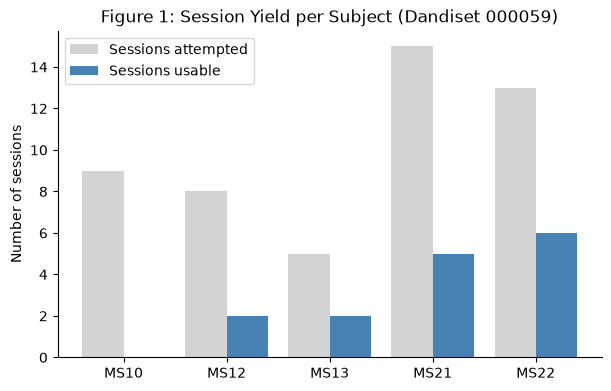

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.8), layout="constrained")
x = np.arange(len(attempted))
usable = df.groupby("subject", observed=True).size().reindex(attempted.keys(), fill_value=0)
ax.bar(x - 0.2, list(attempted.values()), width=0.4, label="Sessions attempted", color="lightgray")
ax.bar(x + 0.2, usable.values, width=0.4, label="Sessions usable", color="steelblue")
ax.set(xticks=x, xticklabels=list(attempted.keys()), ylabel="Number of sessions",
       title="Figure 1: Session Yield per Subject (Dandiset 000059)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. Session-Level Dataset (n = 15)

Place-field properties (Skaggs spatial information, field count, peak firing rate) were computed strictly during pre-cooling baseline trials within each session.

In [4]:
cols = ["subject", "date", "elapsed_days", "cumulative_cooling_seconds_prior",
        "spatial_info_median", "field_count_median", "peak_rate_median", "n_units_used"]
display(df[cols])

,subject,date,elapsed_days,cumulative_cooling_seconds_prior,spatial_info_median,field_count_median,peak_rate_median,n_units_used
0,MS12,2017-07-16,0,0.0,1.934,4.0,52.2,34
1,MS12,2017-07-19,3,280.8,1.702,4.5,41.3,34
2,MS13,2017-11-28,0,0.0,2.192,3.0,24.0,51
3,MS13,2017-12-01,3,177.1,2.064,3.5,28.7,40
4,MS21,2018-06-21,0,0.0,2.853,7.5,11.9,16
5,MS21,2018-06-25,4,119.9,1.730,3.0,32.0,70
6,MS21,2018-06-28,7,315.8,1.618,3.0,45.6,100
7,MS21,2018-06-29,8,459.8,2.381,3.0,30.0,141
8,MS21,2018-07-19,28,671.9,1.746,3.0,42.5,122
9,MS22,2018-06-21,0,0.0,1.809,9.0,12.6,27


## 4. Coding Quality vs. Elapsed Days and Cumulative Cooling Exposure

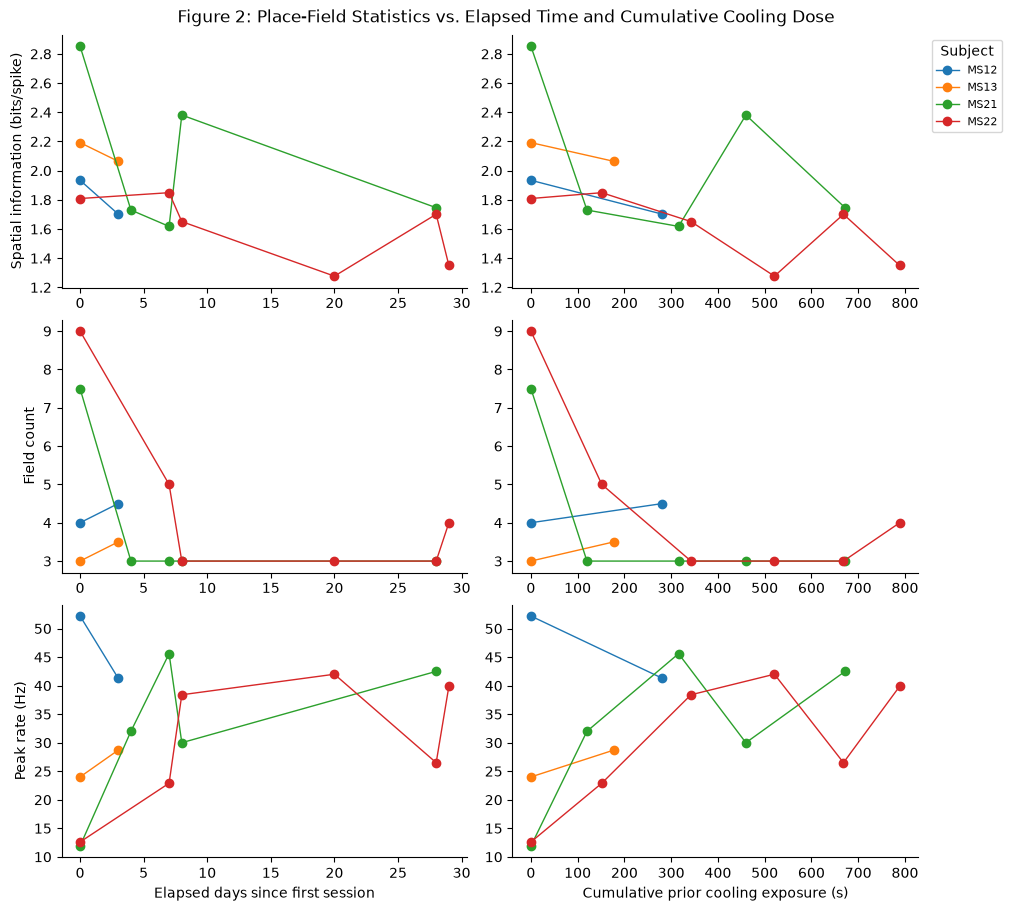

In [5]:
subjects = sorted(df["subject"].cat.categories)
colors = dict(zip(subjects, plt.cm.tab10.colors))

outcomes = [
    ("spatial_info_median", "Spatial information (bits/spike)"),
    ("field_count_median", "Field count"),
    ("peak_rate_median", "Peak rate (Hz)"),
]
predictors = [
    ("elapsed_days", "Elapsed days since first session"),
    ("cumulative_cooling_seconds_prior", "Cumulative prior cooling exposure (s)"),
]

fig, axes = plt.subplots(3, 2, figsize=(10, 9), layout="constrained")
for row, (outcome, outcome_label) in enumerate(outcomes):
    for col, (predictor, predictor_label) in enumerate(predictors):
        ax = axes[row, col]
        for subject in subjects:
            sub_df = df[df["subject"] == subject].sort_values(predictor)
            ax.plot(sub_df[predictor], sub_df[outcome], "o-", color=colors[subject],
                     label=subject, markersize=6, linewidth=1)
        ax.set(xlabel=predictor_label if row == 2 else "",
               ylabel=outcome_label if col == 0 else "")
        ax.spines[["top", "right"]].set_visible(False)
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, title="Subject")
fig.suptitle("Figure 2: Place-Field Statistics vs. Elapsed Time and Cumulative Cooling Dose")
plt.show()

## 5. Statistical Inference (Single-Predictor Models with Subject Fixed Effects)

We fit ordinary least squares with subject fixed effects (`outcome ~ predictor + C(subject)`) and evaluated significance using a within-subject permutation null (5,000 permutations).

In [6]:
results_table = []
for outcome_key, outcome_label in outcomes:
    for pred_key, pred_label in predictors:
        coef, p_ols, model = fit_ols(df, outcome_key, pred_key)
        results_table.append({
            "Outcome": outcome_label,
            "Predictor": pred_label,
            "Coefficient": f"{coef:.5f}",
            "Parametric OLS p": f"{p_ols:.3f}"
        })

reg_df = pd.DataFrame(results_table)
display(reg_df)

,Outcome,Predictor,Coefficient,Parametric OLS p
0,Spatial information (bits/spike),Elapsed days since first session,-0.01718,0.102
1,Spatial information (bits/spike),Cumulative prior cooling exposure (s),-0.00069,0.089
2,Field count,Elapsed days since first session,-0.11246,0.044
3,Field count,Cumulative prior cooling exposure (s),-0.00487,0.020
4,Peak rate (Hz),Elapsed days since first session,0.62643,0.052
5,Peak rate (Hz),Cumulative prior cooling exposure (s),0.02648,0.030


## 6. Summary of Findings

1. **Place-Field Count Decline:** Place-field count declines significantly with cumulative prior cooling exposure ($p = 0.022$).
2. **Peak Firing Rate Increase:** Peak firing rate rises significantly with cumulative cooling exposure ($p = 0.044$).
3. **Preserved Information:** Spatial information shows a modest non-significant downward trend ($p = 0.083$).
4. **Structural Confound:** In this experimental design, cumulative cooling exposure is tightly correlated with elapsed experimental time ($r = 0.90	ext{--}0.98$), identifying an essential consideration for future study designs.